# Churn Radar Exploratory Data Analysis (EDA)

**Objective:** Understand the data, clean it, and discover the core reasons behind customer churn.

---

## 1) Import Libraries

In [465]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Set plotting style and options
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 2) Load Raw Data

In [466]:
RAW_PATH = "..\\..\\data\\raw\\Telco-Customer-Churn.csv"

raw = pd.read_csv(RAW_PATH)
df = raw.copy()

print("Data shape:", df.shape)
df.head(5)

Data shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3) Data Quality Check
Check for missing values, data types, and duplicated rows.

In [467]:
# Check missing values and duplicates
print("Columns data types:")
display(df.dtypes)

print("Missing values per column")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nDuplicated rows count")
print("Duplicates:", df.duplicated().sum())

print("\nChurn distribution")
print(df["Churn"].value_counts())

Columns data types:


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Missing values per column
Series([], dtype: int64)

Duplicated rows count
Duplicates: 0

Churn distribution
Churn
No     5174
Yes    1869
Name: count, dtype: int64


## 4) Data Cleaning & Cleaning Log
Convert *TotalCharges* to numeric and fill empty spaces with 0 for brand new customers (*tenure = 0*).

In [468]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

df["TotalCharges"] = df["TotalCharges"].fillna(0)

df.to_csv("Cleaned_Dataset.csv", index=False)

## 5) Overall Churn Rate & Class Imbalance

Total customers: 7043
Churned customers: 1869
Churn rate: 26.5 %


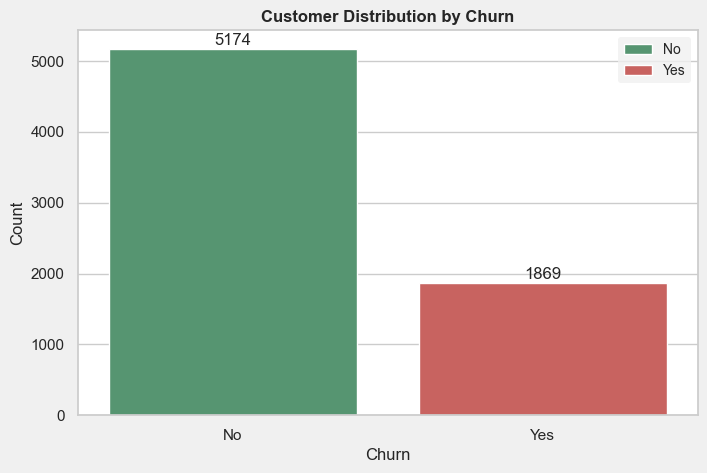

In [469]:
if "Churn_num" not in df.columns:
  df["Churn_num"] = (df["Churn"] == "Yes").astype(int)

total_customers = len(df)
churn_count = df["Churn_num"].sum()
churn_rate = (churn_count / total_customers) * 100

print(f"Total customers: {total_customers}")
print(f"Churned customers: {churn_count}")
print(f"Churn rate:", round(churn_rate, 1), "%")

# Plot churn counts
plt.figure(figsize=(8, 5), facecolor="#F0F0F0")
sns.countplot(x="Churn", hue="Churn", data=df, palette=["#4C9F70", "#D9534F"])
for index, value in enumerate(df["Churn"].value_counts()):
    plt.text(index, value + 10, str(value), ha='center', va='bottom', fontsize=12)
plt.title("Customer Distribution by Churn", fontsize=12, fontweight="bold")
plt.xlabel("Churn")
plt.ylabel("Count")
plt.legend(labels=["No", "Yes"], frameon=True, facecolor="#F0F0F0", edgecolor='none', fontsize=10)
plt.show()

### Data Balance Note:
- The dataset is **moderately imbalanced** (approximately **73.5%** retained vs. **26.5%** churned).
- While the imbalance isn't extreme, relying solely on **Accuracy** can be misleading. 
- Therefore, it is crucial to evaluate future models using metrics like **Recall** and **F1-Score** to ensure we effectively capture churned customers.

## 6) Churn Analysis by Key Features (Contract, Internet, Payment)
function to analyze categorical features and plot their churn rates against the global average.

In [470]:
def analyze_churn(col):
  summary = df.groupby(col)["Churn_num"].agg(["count", "sum", "mean"])
  summary.columns = ["Total_Customers", "Churned_Count", "ChurnRate"]
  summary["ChurnRate"] = (summary["ChurnRate"] * 100).round(1)

  # Plot bar chart
  plt.figure(figsize=(10, 7), facecolor="#F0F0F0")
  sns.barplot(
      x=summary.index.astype(str),
      y=summary["ChurnRate"],
      color="#4C9F70",
  )
  plt.axhline(
      churn_rate,
      color="black",
      linestyle="--",
      label=f"Average ({churn_rate:.1f}%)",
  )
  plt.title(f"Churn Rate by {col}", fontsize=12, fontweight="bold")
  plt.ylabel("Churn Rate")
  plt.legend(frameon=True, facecolor="#F0F0F0", edgecolor='none', fontsize=10)

  for idx, val in enumerate(summary["ChurnRate"]):
    plt.text(idx, val + 0.5, f"{val}%", ha="center")

  plt.show()
  return summary

Contract Analysis


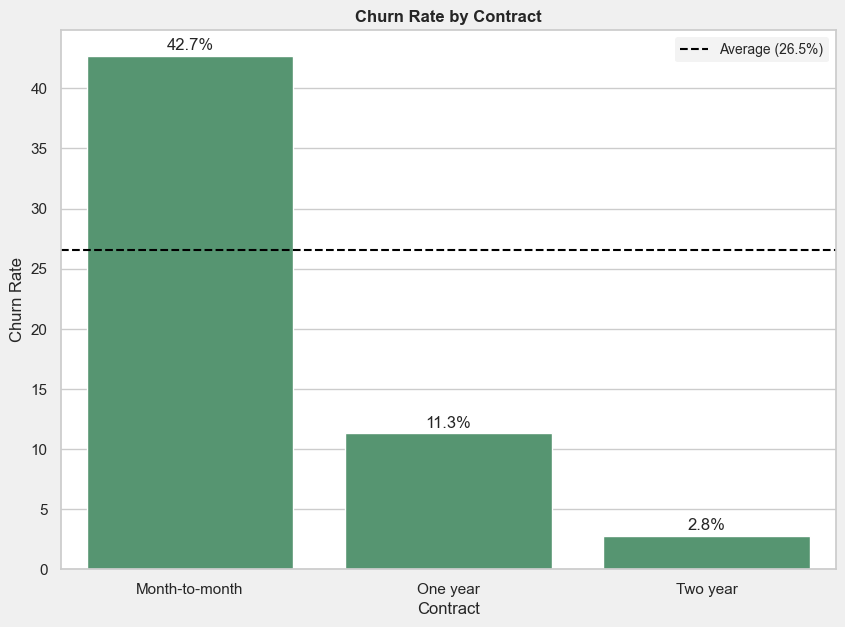

,Total_Customers,Churned_Count,ChurnRate
Contract,,,
Month-to-month,3875,1655,42.7
One year,1473,166,11.3
Two year,1695,48,2.8


In [471]:
print("Contract Analysis")
display(analyze_churn("Contract"))

### Contract Risk Insight:
- **Month-to-month contracts** are the highest risk ($\approx 42.7\%$ churn rate).
- In contrast, long-term contracts show much higher loyalty: **1-year** ($\approx 11.3\%$) and **2-year** ($\approx 2.8\%$).
- **Takeaway:** Customers locked into long-term commitments are significantly more likely to stay.

Internet Service Analysis


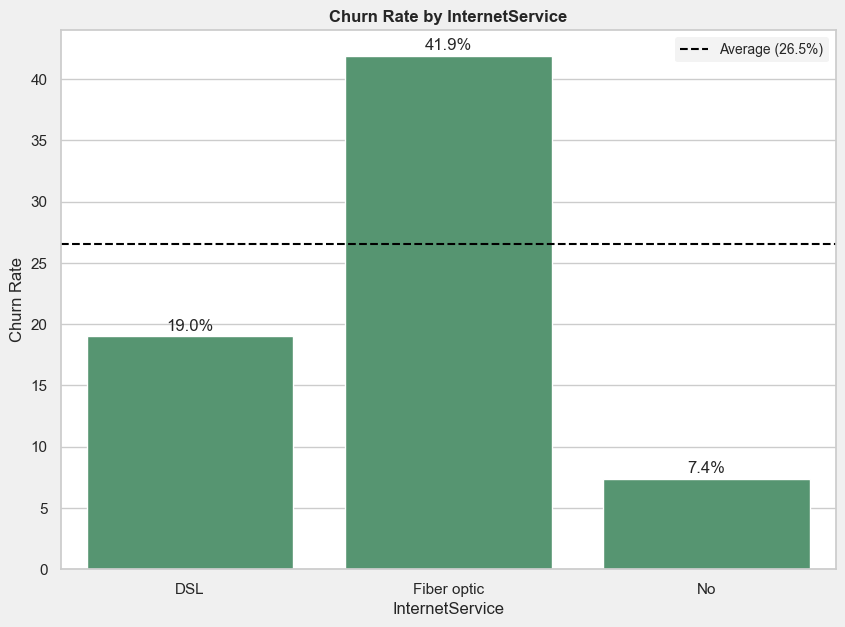

,Total_Customers,Churned_Count,ChurnRate
InternetService,,,
DSL,2421,459,19.0
Fiber optic,3096,1297,41.9
No,1526,113,7.4


In [472]:
print("Internet Service Analysis")
display(analyze_churn("InternetService"))

### Internet Service Insight:
- **Fiber optic** users churn at more than double the rate ($\approx 41.9\%$) compared to **DSL** ($\approx 19.0\%$).
- **Takeaway:** Likely driven by higher pricing or quality issues worth investigating further.

Payment Method Analysis


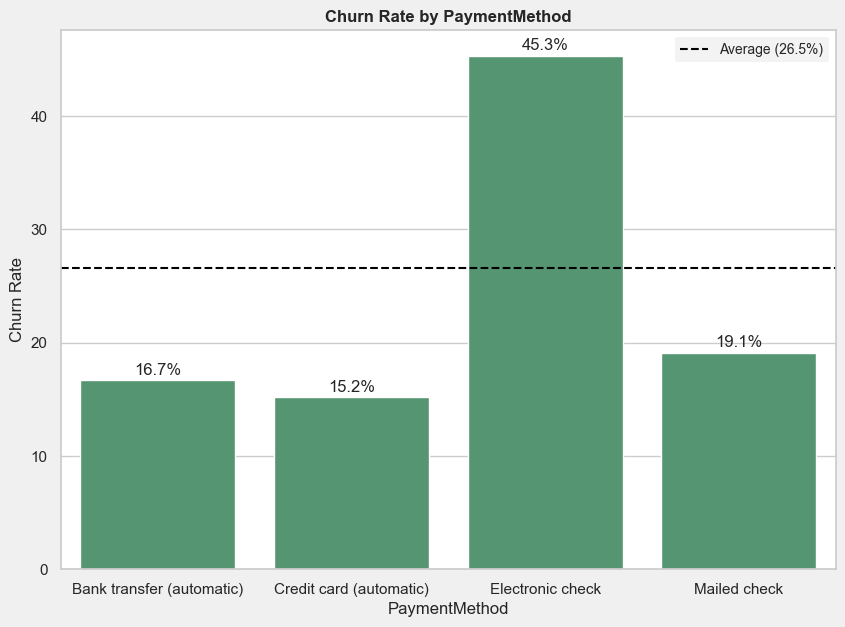

,Total_Customers,Churned_Count,ChurnRate
PaymentMethod,,,
Bank transfer (automatic),1544,258,16.7
Credit card (automatic),1522,232,15.2
Electronic check,2365,1071,45.3
Mailed check,1612,308,19.1


In [473]:
print("Payment Method Analysis")
display(analyze_churn("PaymentMethod"))

### Payment Method Insight:
- **Electronic check** users show the highest churn rate by far ($\approx 45.3\%$).
- In contrast, automatic payment methods (**Bank transfer** and **Credit card**) show much lower churn ($\approx 15\% - 17\%$).
- **Takeaway:** Encouraging customers to switch to automatic payment options can significantly improve retention.

Senior Citizen Analysis


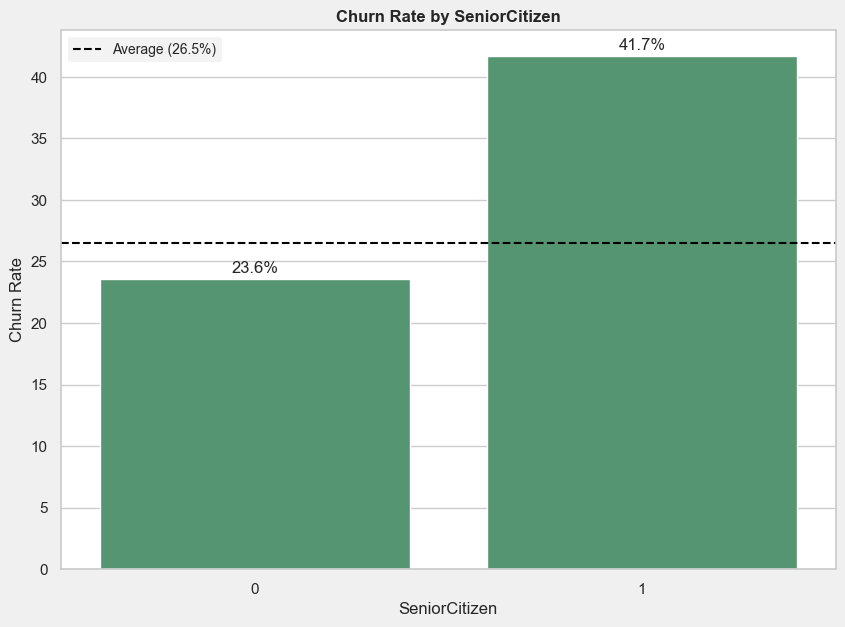

,Total_Customers,Churned_Count,ChurnRate
SeniorCitizen,,,
0,5901,1393,23.6
1,1142,476,41.7


In [474]:
print("Senior Citizen Analysis")
display(analyze_churn("SeniorCitizen"))

Partner Analysis


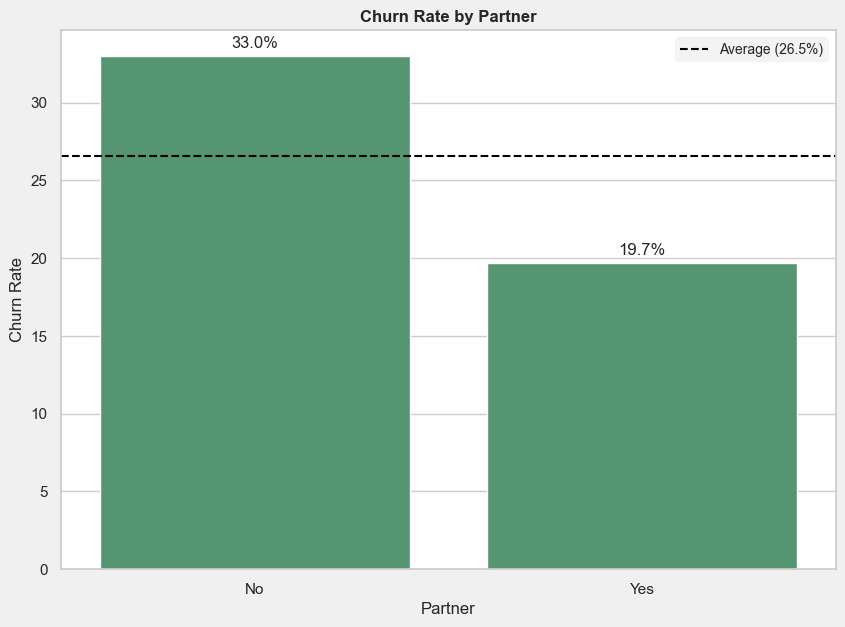

,Total_Customers,Churned_Count,ChurnRate
Partner,,,
No,3641,1200,33.0
Yes,3402,669,19.7


In [475]:
print("Partner Analysis")
display(analyze_churn("Partner"))

Dependents Analysis


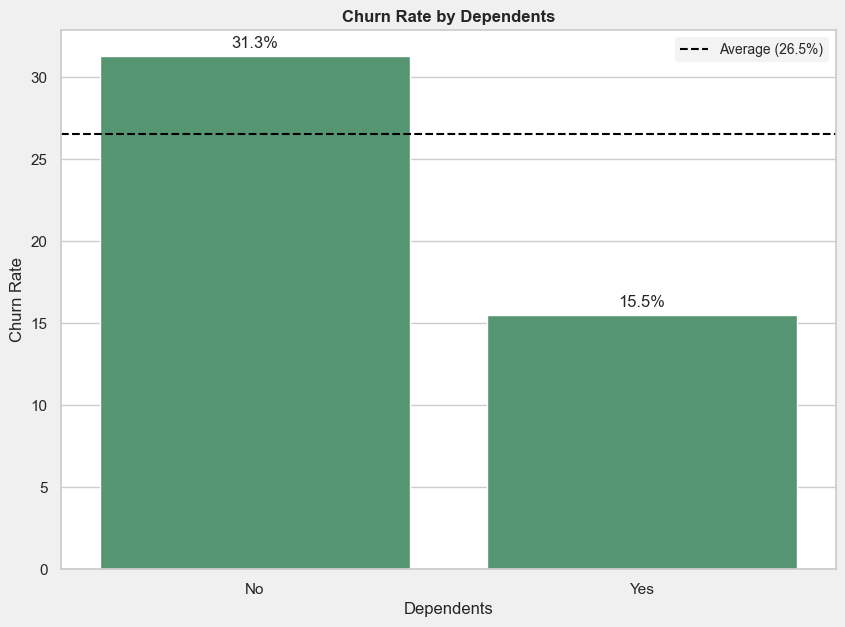

,Total_Customers,Churned_Count,ChurnRate
Dependents,,,
No,4933,1543,31.3
Yes,2110,326,15.5


In [476]:
print("Dependents Analysis")
display(analyze_churn("Dependents"))

Gender Analysis


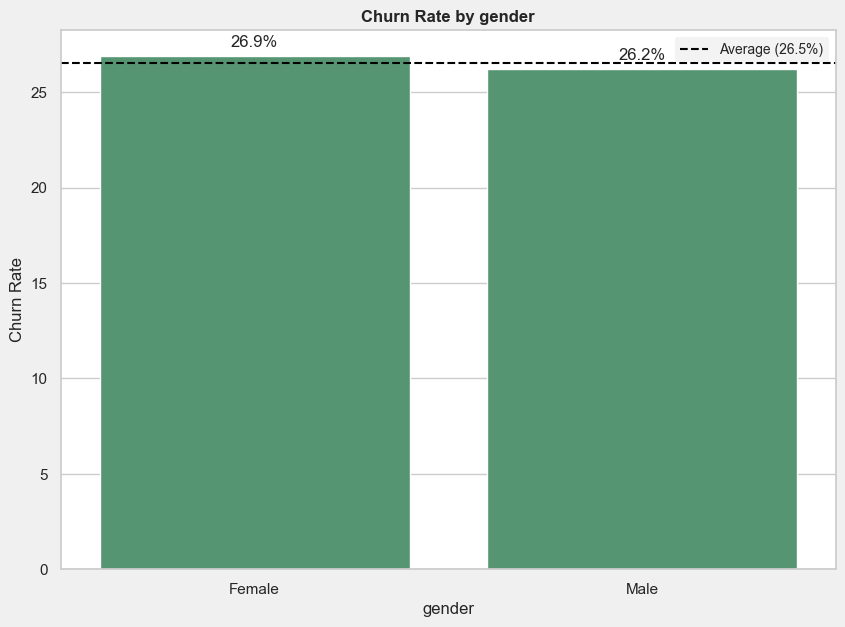

,Total_Customers,Churned_Count,ChurnRate
gender,,,
Female,3488,939,26.9
Male,3555,930,26.2


In [477]:
print("Gender Analysis")
display(analyze_churn("gender"))

,service,churn with service,churn without service
0,OnlineSecurity,14.6,41.8
1,OnlineBackup,21.5,39.9
2,DeviceProtection,22.5,39.1
3,TechSupport,15.2,41.6
4,StreamingTV,30.1,33.5
5,StreamingMovies,29.9,33.7


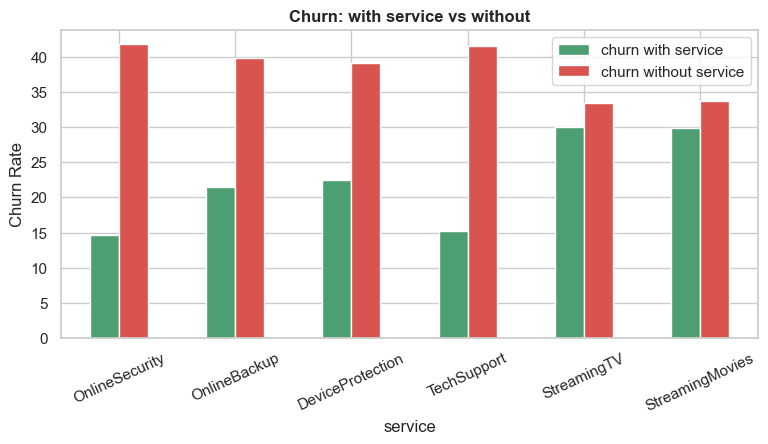

In [478]:
service_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

rows = []
for col in service_cols:
    summary = df.groupby(col)["Churn_num"].agg(["count", "sum", "mean"])
    summary.columns = ["Total_Customers", "Churned_Count", "ChurnRate"]
    summary["ChurnRate"] = (summary["ChurnRate"] * 100).round(1)
    
    rows.append({
        "service": col,
        "churn with service": summary.loc["Yes", "ChurnRate"],
        "churn without service": summary.loc["No", "ChurnRate"]
        })
    
service_table = pd.DataFrame(rows)
display(service_table)

service_table.set_index("service").plot(kind="bar", figsize=(9, 4), color=["#4C9F70", "#D9534F"])
plt.title("Churn: with service vs without", fontsize=12, fontweight="bold")
plt.ylabel("Churn Rate")
plt.xticks(rotation=25)
plt.show()

## 7) Numerical Columns Analysis (Tenure & MonthlyCharges)

,tenure,MonthlyCharges
Churn,,
No,37.6,61.3
Yes,18.0,74.4


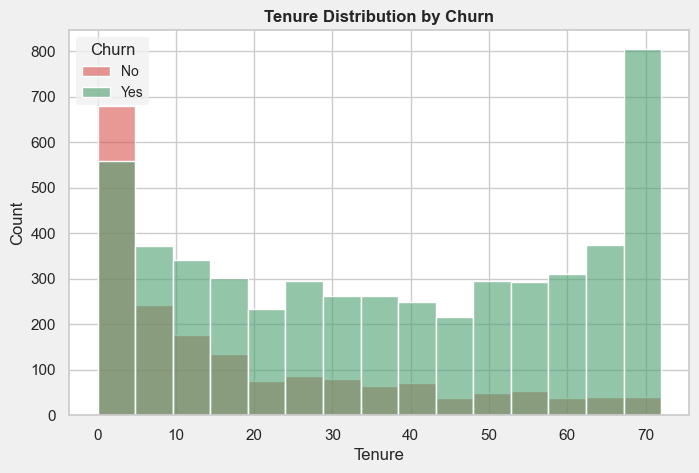

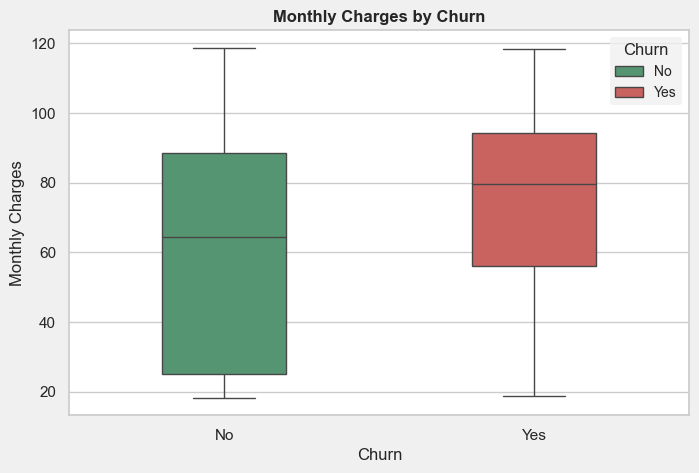

In [479]:
# Compare means between churned and retained customers
display(df.groupby("Churn")[["tenure", "MonthlyCharges"]].mean().round(1))

# Tenure distribution
plt.figure(figsize=(8, 5), facecolor="#F0F0F0")
sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=15,
    palette={"No": "#4C9F70", "Yes": "#D9534F"},
    alpha=0.6,
)
plt.xlabel("Tenure")
plt.ylabel("Count")
plt.title("Tenure Distribution by Churn", fontsize=12, fontweight="bold")
plt.legend(title="Churn", labels=["No", "Yes"], frameon=True, facecolor="#F0F0F0", edgecolor='none', fontsize=10)
plt.show()

# Monthly charges boxplot
plt.figure(figsize=(8, 5), facecolor="#F0F0F0")
sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette={"No": "#4C9F70", "Yes": "#D9534F"},
    width=0.4,
    fliersize=3,
)
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.title("Monthly Charges by Churn", fontsize=12, fontweight="bold")
plt.legend(title="Churn", labels=["No", "Yes"], frameon=True, facecolor="#F0F0F0", edgecolor='none', fontsize=10)
# plt.tight_layout()
plt.show()

## 8) Customer Segmentation & Revenue at Risk

,risk_segment,Total_Customers,Churned_Count,Churn_Rate,Monthly_Revenue_Lost
0,High Risk,1994,1024,51.4,68301.45
2,Medium Risk,1881,631,33.5,52545.65
1,Low Risk,3168,214,6.8,18283.75



Total Monthly Revenue Lost: 139,131 out of 456,117 (30.5%)


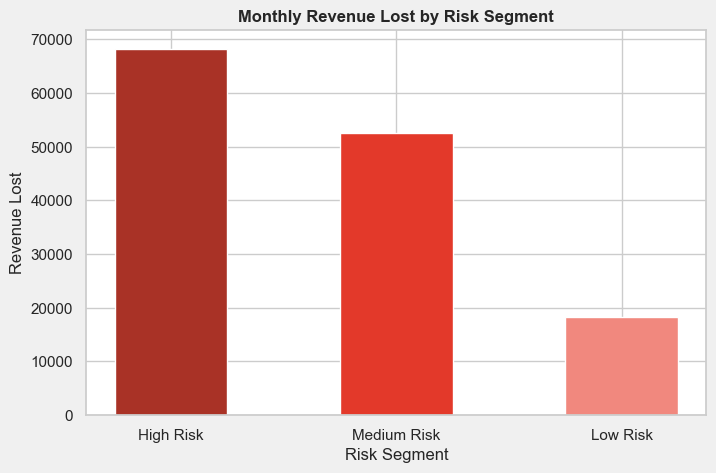

In [480]:

# Define the risk segment function
def get_risk_segment(row):
  if row["Contract"] == "Month-to-month" and row["tenure"] <= 12:
    return "High Risk"
  elif row["Contract"] == "Month-to-month":
    return "Medium Risk"
  else:
    return "Low Risk"

df["risk_segment"] = df.apply(get_risk_segment, axis=1)
df["Lost_Revenue"] = df["MonthlyCharges"] * df["Churn_num"]

seg_analysis = df.groupby("risk_segment").agg(
        Total_Customers=("customerID", "count"),
        Churned_Count=("Churn_num", "sum"),
        Total_Monthly_Charges=("MonthlyCharges", "sum"),
        Monthly_Revenue_Lost=("Lost_Revenue", "sum"),
    ).reset_index()

seg_analysis["Churn_Rate"] = (seg_analysis["Churned_Count"] / seg_analysis["Total_Customers"] * 100).round(1)

risk_order = ["High Risk", "Medium Risk", "Low Risk"]
seg_analysis["risk_segment"] = pd.Categorical(
    seg_analysis["risk_segment"], categories=risk_order, ordered=True
)
seg_analysis = seg_analysis.sort_values("risk_segment")

seg_analysis = seg_analysis[
    [
        "risk_segment",
        "Total_Customers",
        "Churned_Count",
        "Churn_Rate",
        "Monthly_Revenue_Lost",
    ]
]

display(seg_analysis)

total_lost = df[df["Churn_num"] == 1]["MonthlyCharges"].sum()
total_rev = df["MonthlyCharges"].sum()
print(f"\nTotal Monthly Revenue Lost: {total_lost:,.0f} out of {total_rev:,.0f} ({total_lost / total_rev * 100:.1f}%)")

plt.figure(figsize=(8, 5), facecolor="#F0F0F0")

plt.bar(
    seg_analysis["risk_segment"],
    seg_analysis["Monthly_Revenue_Lost"],
    width=0.5,
    color=["#A93226", "#E3392A", "#F1887E"],
)
plt.title("Monthly Revenue Lost by Risk Segment", fontsize=12, fontweight="bold")
plt.xlabel("Risk Segment")
plt.ylabel("Revenue Lost")
plt.show()

## 9) Summary & Recommendations

* **Overall Churn Rate:** 26.5% (1,869 out of 7,043 customers)

* **High-Risk Profile:** 
  - **Tenure & Contract:** New customers (within their first 12 months) on **Month-to-month contracts**.
  - **Internet Service:** **Fiber optic** users (showing significantly higher churn).
  - **Payment Method:** Paying via **Electronic check**.
  - **Add-ons & Demographics:** Lacking critical services like *TechSupport* or *OnlineSecurity*.
  - **Note on Irrelevance:** Features like *gender* and *PhoneService* showed no meaningful impact on churn.

* **Key Recommendations:** 
  1. **Contract Shift:** Offer financial incentives or discounts to transition month-to-month users to long-term (1 or 2 years) contracts.
  2. **Onboarding Focus:** Implement proactive check-ins and onboarding support during the critical first 12 months.
  3. **Payment Optimization:** Encourage customers to switch from Electronic checks to automated payment methods.
  4. **Value-Added Services:** Bundle *TechSupport* or *OnlineSecurity* (e.g., free trials) for new sign-ups.
  5. **Fiber Optic Review:** Investigate pricing tiers and service quality for Fiber optic packages.